# Project 1: Evaluation and figures

Reads the results saved by the five learner notebooks (`results/*.npz`) and draws the pipeline, the comparison of the learners and the diagnostic of the best one. Figures go to `figures/`.

## Pipeline diagram

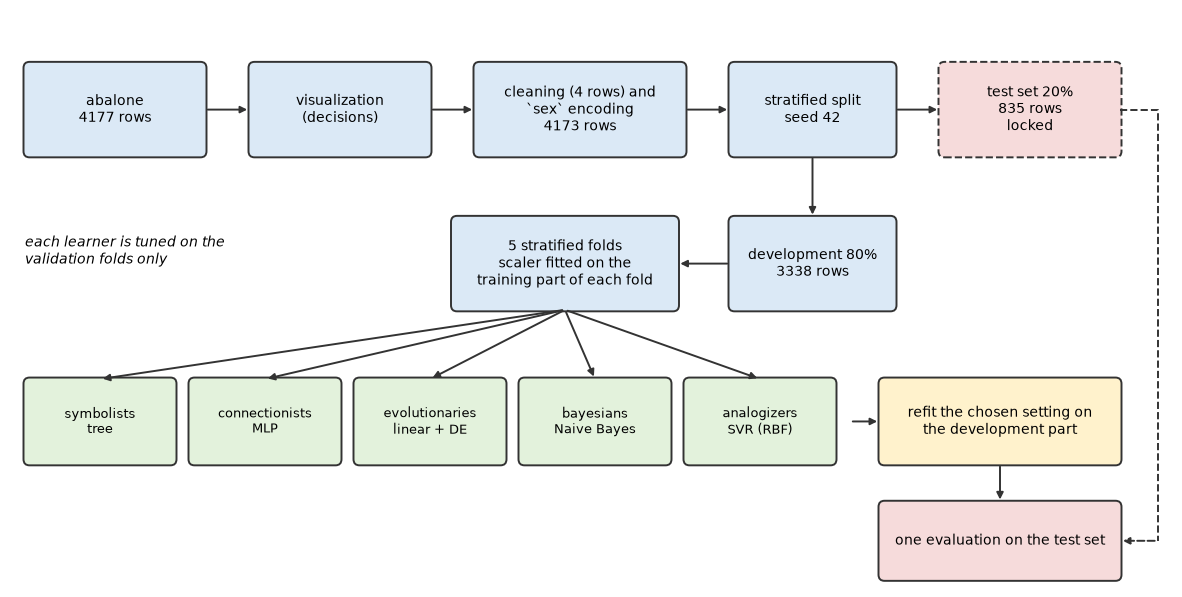

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from matplotlib.patches import FancyBboxPatch
from pathlib import Path

Path("figures").mkdir(exist_ok=True)


def box(ax, x, y, w, h, text, color="#dbe9f6", ls="-", fs=10):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=color, ec="#333", lw=1.4, ls=ls))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs)


def arrow(ax, x0, y0, x1, y1, ls="-"):
    ax.annotate("", (x1, y1), (x0, y0), arrowprops=dict(arrowstyle="-|>", color="#333", lw=1.4, ls=ls))


fig, ax = plt.subplots(figsize=(15, 7.5))
ax.set(xlim=(0, 15.5), ylim=(0, 7.5)); ax.axis("off")

# row 1: data to split
box(ax, 0.2, 5.6, 2.4, 1.2, "abalone\n4177 rows")
box(ax, 3.2, 5.6, 2.4, 1.2, "visualization\n(decisions)")
box(ax, 6.2, 5.6, 2.8, 1.2, "cleaning (4 rows) and\n`sex` encoding\n4173 rows")
box(ax, 9.6, 5.6, 2.2, 1.2, "stratified split\nseed 42")
for a, b in [(2.6, 3.2), (5.6, 6.2), (9.0, 9.6)]:
    arrow(ax, a, 6.2, b, 6.2)

# test branch
box(ax, 12.4, 5.6, 2.4, 1.2, "test set 20%\n835 rows\nlocked", color="#f6dbdb", ls="--")
arrow(ax, 11.8, 6.2, 12.4, 6.2)

# development branch
box(ax, 9.6, 3.6, 2.2, 1.2, "development 80%\n3338 rows")
arrow(ax, 10.7, 5.6, 10.7, 4.8)
box(ax, 5.9, 3.6, 3.0, 1.2, "5 stratified folds\nscaler fitted on the\ntraining part of each fold")
arrow(ax, 9.6, 4.2, 8.9, 4.2)

# learners
names = ["symbolists\ntree", "connectionists\nMLP", "evolutionaries\nlinear + DE", "bayesians\nNaive Bayes", "analogizers\nSVR (RBF)"]
for k, t in enumerate(names):
    box(ax, 0.2 + k * 2.2, 1.6, 2.0, 1.1, t, color="#e3f2dc", fs=9)
    arrow(ax, 7.4, 3.6, 1.2 + k * 2.2, 2.7)
ax.text(0.2, 4.2, "each learner is tuned on the\nvalidation folds only", ha="left", fontsize=10, style="italic")

# refit and test
box(ax, 11.6, 1.6, 3.2, 1.1, "refit the chosen setting on\nthe development part", color="#fff2cc")
arrow(ax, 11.2, 2.15, 11.6, 2.15)
box(ax, 11.6, 0.1, 3.2, 1.0, "one evaluation on the test set", color="#f6dbdb")
arrow(ax, 13.2, 1.6, 13.2, 1.1)
ax.plot([14.8, 15.3, 15.3], [6.2, 6.2, 0.6], "--", color="#333", lw=1.4)
arrow(ax, 15.3, 0.6, 14.8, 0.6, ls="--")
fig.savefig("figures/pipeline.png", dpi=150, bbox_inches="tight")
plt.show()

## Comparison of the five learners

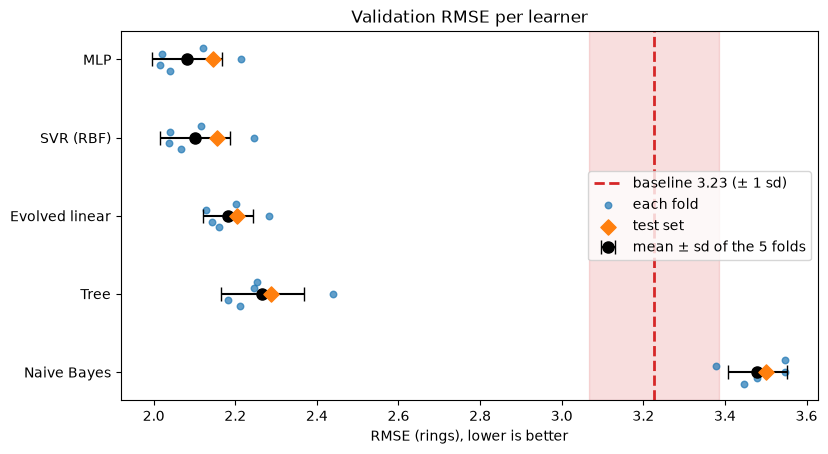

In [2]:
LEARNERS = {"symbolists": "Tree", "connectionists": "MLP", "evolutionaries": "Evolved linear", "bayesians": "Naive Bayes", "analogizers": "SVR (RBF)"}
res = {k: np.load(f"results/{k}.npz") for k in LEARNERS}
rmse = lambda y, p: np.sqrt(np.mean((y - p) ** 2))
base = res["symbolists"]["baseline_rmse"]
order = sorted(LEARNERS, key=lambda k: res[k]["val_rmse"].mean())

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.axvspan(base.mean() - base.std(ddof=1), base.mean() + base.std(ddof=1), color="C3", alpha=0.15)
ax.axvline(base.mean(), color="C3", ls="--", lw=2, label=f"baseline {base.mean():.2f} (± 1 sd)")
for row, k in enumerate(order):
    v, d = res[k]["val_rmse"], res[k]
    ax.errorbar(v.mean(), row, xerr=v.std(ddof=1), fmt="o", color="k", capsize=5, ms=8, zorder=3, label="mean ± sd of the 5 folds" if row == 0 else None)
    ax.scatter(v, np.full(5, row) + np.linspace(-0.15, 0.15, 5), s=22, color="C0", alpha=0.7, zorder=2, label="each fold" if row == 0 else None)
    ax.scatter(rmse(d["test_y"], d["test_pred"]), row, marker="D", s=60, color="C1", zorder=4, label="test set" if row == 0 else None)
ax.set(yticks=range(len(order)), yticklabels=[LEARNERS[k] for k in order], xlabel="RMSE (rings), lower is better", title="Validation RMSE per learner")
ax.invert_yaxis(); ax.legend(loc="center right")
fig.savefig("figures/comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## Diagnostic of the best learner (MLP)

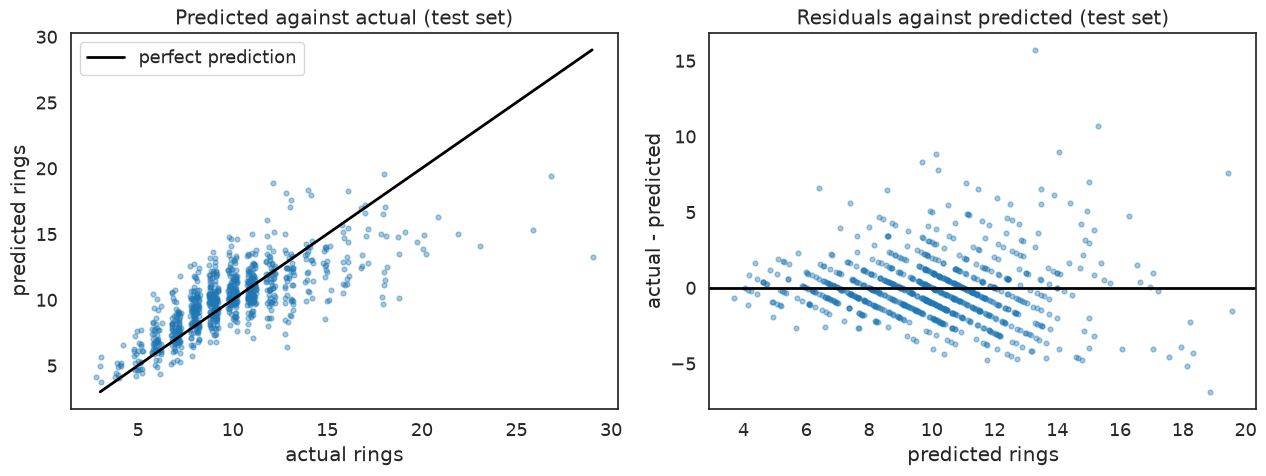

In [3]:
d = res["connectionists"]
y, p = d["test_y"], d["test_pred"]
resid = y - p
jitter = np.random.default_rng(42).uniform(-0.25, 0.25, len(y))  # rings are integers

with sns.axes_style("white"), sns.plotting_context("notebook", font_scale=1.2):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
    ax1.scatter(y + jitter, p, s=12, alpha=0.4)
    ax1.plot([y.min(), y.max()], [y.min(), y.max()], "k", lw=2, label="perfect prediction")
    ax1.set(title="Predicted against actual (test set)", xlabel="actual rings", ylabel="predicted rings"); ax1.legend()
    ax2.scatter(p, resid, s=12, alpha=0.4)
    ax2.axhline(0, color="k", lw=2)
    ax2.set(title="Residuals against predicted (test set)", xlabel="predicted rings", ylabel="actual - predicted")
    fig.tight_layout()
    fig.savefig("figures/diagnostic_mlp.png", dpi=150, bbox_inches="tight")
    plt.show()

### Error by age

MAE of every learner on the test set, for groups of animals by their actual rings.

In [4]:
groups = [("<= 7", y <= 7), ("8 to 10", (y >= 8) & (y <= 10)), ("11 to 13", (y >= 11) & (y <= 13)), (">= 14", y >= 14)]
print(f"{'rings':9s}{'animals':>8s}" + "".join(f"{LEARNERS[k]:>16s}" for k in order))
for name, m in groups:
    print(f"{name:9s}{m.sum():8d}" + "".join(f"{np.abs(res[k]['test_y'][m] - res[k]['test_pred'][m]).mean():16.2f}" for k in order))
print("\nMLP mean residual (actual - predicted) by group:")
for name, m in groups:
    print(f"  {name:9s}{resid[m].mean():6.2f}")

rings     animals             MLP       SVR (RBF)  Evolved linear            Tree     Naive Bayes
<= 7          175            1.12            1.08            1.17            1.15            2.25
8 to 10       356            1.30            1.27            1.33            1.36            2.63
11 to 13      216            1.37            1.36            1.56            1.39            3.25
>= 14          88            3.47            3.62            3.70            3.94            4.02

MLP mean residual (actual - predicted) by group:
  <= 7      -0.85
  8 to 10   -0.92
  11 to 13   0.45
  >= 14      3.18
